Total deliveries: 87690
Available seasons: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

Innings statistics:
   match_id       date  season  innings                 batting_team  \
0   1304047 2022-03-26    2022        1          Chennai Super Kings   
1   1304047 2022-03-26    2022        2        Kolkata Knight Riders   
2   1304048 2022-03-27    2022        1               Mumbai Indians   
3   1304048 2022-03-27    2022        2               Delhi Capitals   
4   1304049 2022-03-27    2022        1  Royal Challengers Bengaluru   

   total_runs  batter_runs  legal_balls  wickets  boundaries  dot_balls  \
0         131          125          120        5          15         55   
1         133          129          111        4          15         42   
2         177          174          120        5          24         37   
3         179          168          110        6          25         38   
4         205          182          120        

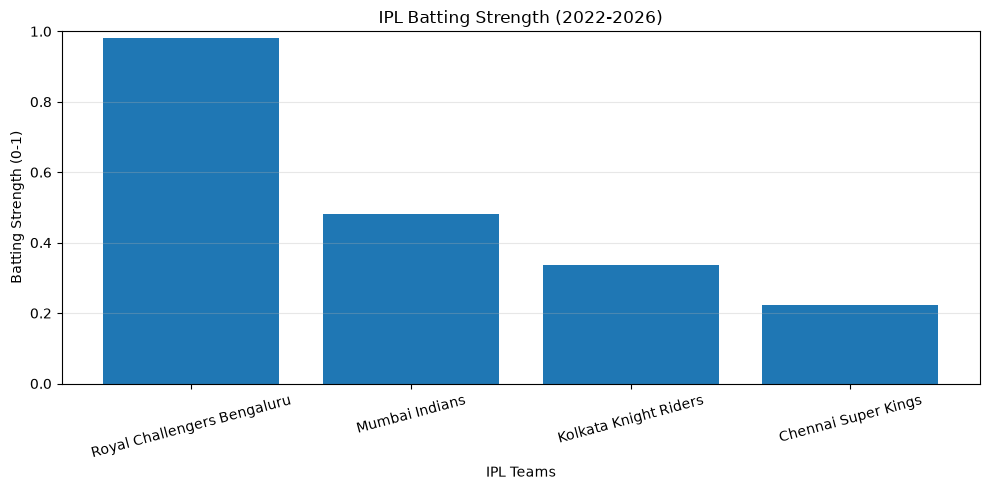


All files saved successfully!


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline


# ==========================================
# 1. LOAD DATA
# ==========================================

df = pd.read_csv("ipl_ball_by_ball.csv")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Use match year as season
df["season"] = df["date"].dt.year

df = df[df["season"].between(2022, 2026)].copy()

# Standardize RCB name
df["batting_team"] = df["batting_team"].replace({
    "Royal Challengers Bangalore":
    "Royal Challengers Bengaluru"
})

teams = [
    "Royal Challengers Bengaluru",
    "Chennai Super Kings",
    "Mumbai Indians",
    "Kolkata Knight Riders"
]

print("Total deliveries:", len(df))
print("Available seasons:", sorted(df["season"].unique()))


# ==========================================
# 2. PREPARE DELIVERY DATA
# ==========================================

required_columns = [
    "match_id", "date", "season", "innings",
    "batting_team", "batsman_runs", "total_runs",
    "is_wicket", "wide_runs", "noball_runs"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError("Missing columns: " + str(missing))

numeric_cols = [
    "batsman_runs", "total_runs", "is_wicket",
    "wide_runs", "noball_runs"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Legal deliveries
df["legal_ball"] = (
    (df["wide_runs"] == 0) &
    (df["noball_runs"] == 0)
).astype(int)

# Boundary deliveries
df["boundary"] = (
    df["batsman_runs"].isin([4, 6])
).astype(int)

# Dot deliveries
df["dot_ball"] = (
    (df["total_runs"] == 0) &
    (df["legal_ball"] == 1)
).astype(int)


# ==========================================
# 3. CALCULATE INNINGS STATISTICS
# ==========================================

group_columns = [
    "match_id",
    "date",
    "season",
    "innings",
    "batting_team"
]

innings = (
    df.groupby(group_columns)
    .agg(
        total_runs=("total_runs", "sum"),
        batter_runs=("batsman_runs", "sum"),
        legal_balls=("legal_ball", "sum"),
        wickets=("is_wicket", "sum"),
        boundaries=("boundary", "sum"),
        dot_balls=("dot_ball", "sum")
    )
    .reset_index()
)

# Five batting metrics

innings["avg_runs"] = innings["total_runs"]

innings["strike_rate"] = (
    innings["batter_runs"] /
    innings["legal_balls"].clip(lower=1) * 100
)

innings["boundary_pct"] = (
    innings["boundaries"] /
    innings["legal_balls"].clip(lower=1) * 100
)

innings["runs_per_wicket"] = (
    innings["total_runs"] /
    innings["wickets"].clip(lower=1)
)

innings["dot_pct"] = (
    innings["dot_balls"] /
    innings["legal_balls"].clip(lower=1) * 100
)

features = [
    "avg_runs",
    "strike_rate",
    "boundary_pct",
    "runs_per_wicket",
    "dot_pct"
]

print("\nInnings statistics:")
print(innings.head())


# ==========================================
# 4. CREATE HISTORICAL FEATURES
# ==========================================

innings = innings.sort_values(
    ["date", "match_id", "innings"]
).copy()

for col in features:

    innings["prev_" + col] = (
        innings.groupby("batting_team")[col]
        .transform(
            lambda x: x.shift(1).expanding().mean()
        )
    )

historical_features = [
    "prev_" + col for col in features
]

model_data = innings.dropna(
    subset=historical_features
).copy()

if len(model_data) < 20:
    raise ValueError("Not enough historical innings to train the model.")

print("\nHistorical training rows:", len(model_data))


# ==========================================
# 5. RIDGE REGRESSION
# ==========================================

X = model_data[historical_features]

y = model_data["total_runs"]

model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
])

model.fit(X, y)

# Extract coefficients
coefficients = np.abs(
    model.named_steps["ridge"].coef_
)

# Convert coefficients into weights
if coefficients.sum() == 0:
    weights = np.ones(len(features)) / len(features)
else:
    weights = coefficients / coefficients.sum()

weight_table = pd.DataFrame({
    "Feature": features,
    "Weight": weights
})

print("\n========== LEARNED BATTING WEIGHTS ==========")
print(weight_table.to_string(index=False))


# ==========================================
# 6. SEASON-WISE TEAM PERFORMANCE
# ==========================================

season_stats = (
    innings.groupby(["batting_team", "season"])[features]
    .mean()
    .reset_index()
)

# Importance of each season
season_weights = {
    2022: 0.10,
    2023: 0.15,
    2024: 0.20,
    2025: 0.25,
    2026: 0.30
}

season_stats["season_weight"] = (
    season_stats["season"].map(season_weights)
)

# Calculate weighted metrics for each team
final_stats = []

for team in teams:

    temp = season_stats[
        season_stats["batting_team"] == team
    ].copy()

    if temp.empty:
        print("WARNING: No data found for", team)
        continue

    # Renormalize if any season is missing
    temp = temp.dropna(subset=["season_weight"])

    temp["season_weight"] = (
        temp["season_weight"] /
        temp["season_weight"].sum()
    )

    row = {"Team": team}

    for col in features:
        row[col] = (
            temp[col] * temp["season_weight"]
        ).sum()

    final_stats.append(row)

final_stats = pd.DataFrame(final_stats)

if len(final_stats) != 4:
    raise ValueError(
        "Some teams are missing. Check the team names in your CSV."
    )

print("\n========== WEIGHTED TEAM METRICS ==========")
print(final_stats.to_string(index=False))


# ==========================================
# 7. NORMALIZE METRICS (0 TO 1)
# ==========================================

normalized = final_stats.copy()

for col in features:

    mn = final_stats[col].min()
    mx = final_stats[col].max()

    if mx == mn:
        normalized[col] = 0.5

    elif col == "dot_pct":

        # Lower dot-ball percentage is better
        normalized[col] = (
            (mx - final_stats[col]) / (mx - mn)
        )

    else:

        # Higher is better
        normalized[col] = (
            (final_stats[col] - mn) / (mx - mn)
        )


# ==========================================
# 8. CALCULATE FINAL BATTING STRENGTH
# ==========================================

normalized["Batting_Strength"] = (
    normalized[features].to_numpy() @ weights
)

result = normalized[
    ["Team", "Batting_Strength"]
].copy()

result["Batting_Strength"] = (
    result["Batting_Strength"].round(4)
)

result = result.sort_values(
    "Batting_Strength",
    ascending=False
).reset_index(drop=True)

print("\n======================================")
print("       FINAL IPL BATTING STRENGTH")
print("======================================")

print(result.to_string(index=False))


# ==========================================
# 9. VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 5))

plt.bar(
    result["Team"],
    result["Batting_Strength"]
)

plt.ylim(0, 1)
plt.xlabel("IPL Teams")
plt.ylabel("Batting Strength (0-1)")
plt.title("IPL Batting Strength (2022-2026)")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# 10. SAVE RESULTS
# ==========================================

result.to_csv(
    "ipl_batting_strength.csv",
    index=False
)

weight_table.to_csv(
    "ipl_batting_weights.csv",
    index=False
)

final_stats.to_csv(
    "ipl_batting_raw_metrics.csv",
    index=False
)

print("\nAll files saved successfully!")


Ridge-derived bowling weights:
      Metric   Weight
     economy 0.693030
     wickets 0.053201
  bowling_sr 0.014704
     dot_pct 0.042687
boundary_pct 0.196379

Final Bowling Strength:
               bowling_team  bowling_strength
      Kolkata Knight Riders          0.953222
        Chennai Super Kings          0.712180
Royal Challengers Bengaluru          0.379086
             Mumbai Indians          0.019780

All files saved successfully!


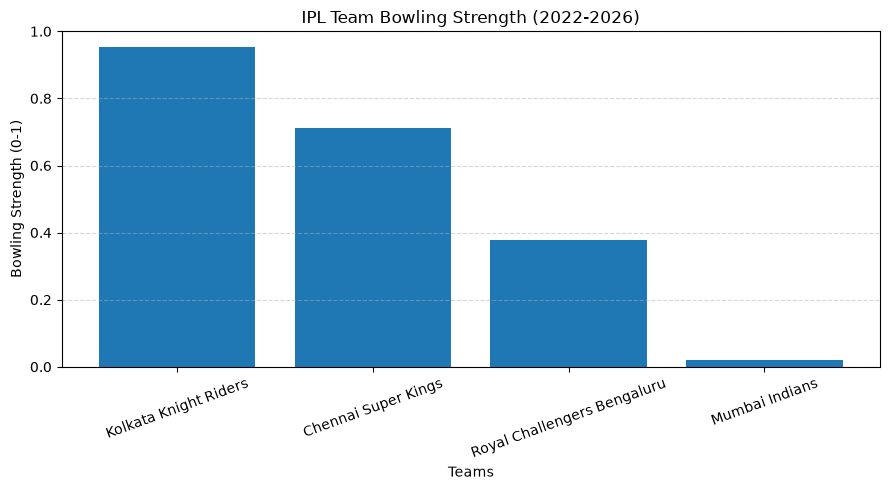

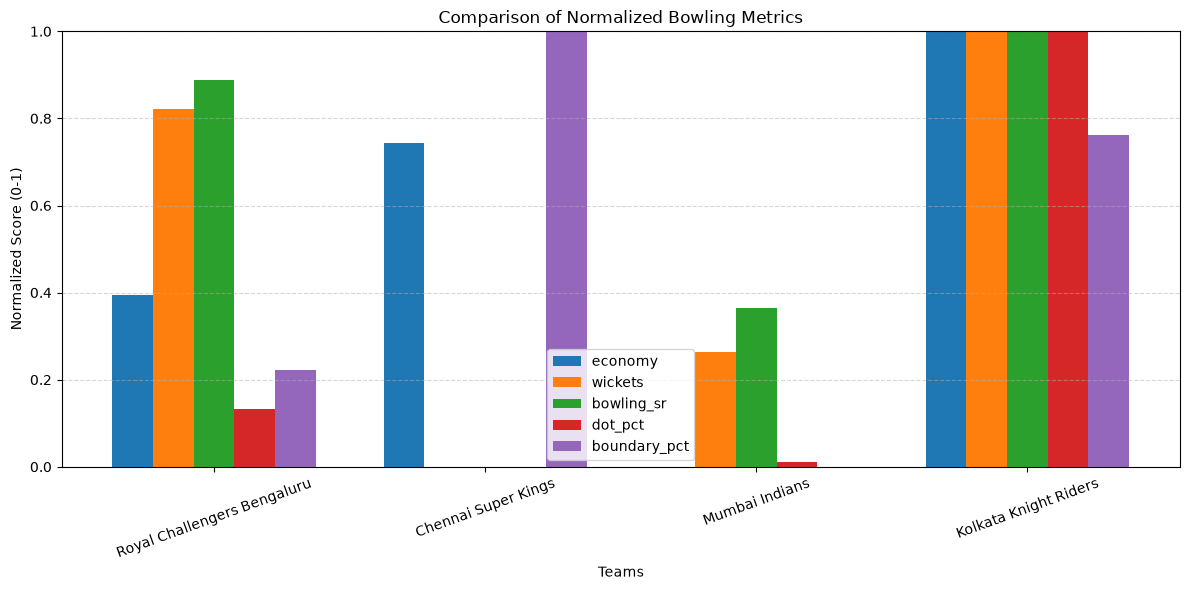

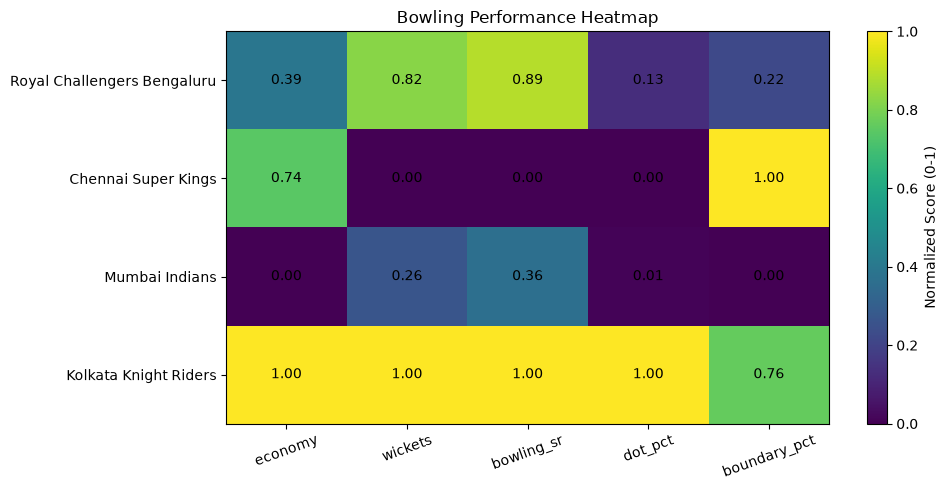

In [3]:

import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge

# ==========================================
# 1. LOAD DATA
# ==========================================

df = pd.read_csv("ipl_ball_by_ball.csv")

df["date"] = pd.to_datetime(df["date"])
df["season"] = df["date"].dt.year

df["batting_team"] = df["batting_team"].replace({
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru"
})

df["bowling_team"] = df["bowling_team"].replace({
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru"
})

teams = [
    "Royal Challengers Bengaluru",
    "Chennai Super Kings",
    "Mumbai Indians",
    "Kolkata Knight Riders"
]

df = df[
    (df["season"].between(2022, 2026)) &
    (df["bowling_team"].isin(teams))
].copy()

# ==========================================
# 2. CALCULATE INNINGS-LEVEL BOWLING METRICS
# ==========================================

# Legal delivery: wides and no-balls are not legal balls
df["legal_ball"] = (
    (df["wide_runs"] == 0) &
    (df["noball_runs"] == 0)
)

# Runs conceded by the bowling team
# Byes and leg-byes are not charged to the bowler
df["runs_conceded"] = (
    df["total_runs"] -
    df["bye_runs"] -
    df["legbye_runs"]
)

# Wickets credited to the bowler
bowler_wicket_types = [
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket"
]

df["bowler_wicket"] = (
    df["dismissal_kind"]
    .fillna("")
    .str.lower()
    .isin(bowler_wicket_types)
    .astype(int)
)

# Dot balls: legal deliveries on which no run was scored
df["dot_ball"] = (
    (df["legal_ball"]) &
    (df["total_runs"] == 0)
).astype(int)

# Boundary balls on legal deliveries
df["boundary"] = (
    (df["legal_ball"]) &
    (df["batsman_runs"].isin([4, 6]))
).astype(int)

# ==========================================
# 3. GROUP BY MATCH INNINGS AND BOWLING TEAM
# ==========================================

group_cols = [
    "match_id",
    "date",
    "season",
    "innings",
    "bowling_team"
]

bowling = df.groupby(group_cols).agg(
    runs_conceded=("runs_conceded", "sum"),
    legal_balls=("legal_ball", "sum"),
    wickets=("bowler_wicket", "sum"),
    dot_balls=("dot_ball", "sum"),
    boundaries=("boundary", "sum")
).reset_index()

# Avoid division by zero
bowling["economy"] = np.where(
    bowling["legal_balls"] > 0,
    bowling["runs_conceded"] / bowling["legal_balls"] * 6,
    np.nan
)

bowling["bowling_sr"] = np.where(
    bowling["wickets"] > 0,
    bowling["legal_balls"] / bowling["wickets"],
    np.nan
)

bowling["dot_pct"] = np.where(
    bowling["legal_balls"] > 0,
    bowling["dot_balls"] / bowling["legal_balls"] * 100,
    np.nan
)

bowling["boundary_pct"] = np.where(
    bowling["legal_balls"] > 0,
    bowling["boundaries"] / bowling["legal_balls"] * 100,
    np.nan
)

# ==========================================
# 4. CREATE HISTORICAL FEATURES
# ==========================================

metrics = [
    "economy",
    "wickets",
    "bowling_sr",
    "dot_pct",
    "boundary_pct"
]

# Sort chronologically
bowling = bowling.sort_values(["date", "match_id", "innings"])

# Previous historical average for each bowling team
for col in metrics:
    bowling["prev_" + col] = (
        bowling.groupby("bowling_team")[col]
        .transform(lambda x: x.shift(1).expanding().mean())
    )

# ==========================================
# 5. TRAIN RIDGE REGRESSION
# ==========================================

feature_cols = ["prev_" + col for col in metrics]

model_data = bowling.dropna(
    subset=feature_cols + ["runs_conceded"]
).copy()

X = model_data[feature_cols]
y = model_data["runs_conceded"]

# Remove infinite values if any
X = X.replace([np.inf, -np.inf], np.nan)
valid = X.notna().all(axis=1) & y.notna()

X = X.loc[valid]
y = y.loc[valid]

model = Ridge(alpha=1.0)
model.fit(X, y)

# Use absolute coefficients as metric importance
coefficients = np.abs(model.coef_)

if coefficients.sum() == 0:
    weights = np.ones(len(metrics)) / len(metrics)
else:
    weights = coefficients / coefficients.sum()

weight_df = pd.DataFrame({
    "Metric": metrics,
    "Weight": weights
})

print("Ridge-derived bowling weights:")
print(weight_df.to_string(index=False))

# ==========================================
# 6. SEASON-WISE TEAM AVERAGES
# ==========================================

season_stats = bowling.groupby(
    ["season", "bowling_team"]
)[metrics].mean().reset_index()

# Recency weights
season_weights = {
    2022: 0.10,
    2023: 0.15,
    2024: 0.20,
    2025: 0.25,
    2026: 0.30
}

# Use only available seasons and renormalize weights
available_seasons = sorted(season_stats["season"].unique())

total_weight = sum(
    season_weights[s] for s in available_seasons
)

season_weights = {
    s: season_weights[s] / total_weight
    for s in available_seasons
}

# ==========================================
# 7. RECENCY-WEIGHTED TEAM METRICS
# ==========================================

final_stats = []

for team in teams:

    team_data = season_stats[
        season_stats["bowling_team"] == team
    ]

    row = {"bowling_team": team}

    for metric in metrics:

        weighted_sum = 0
        total_used_weight = 0

        for _, record in team_data.iterrows():

            value = record[metric]

            if pd.notna(value) and np.isfinite(value):
                w = season_weights[record["season"]]

                weighted_sum += value * w
                total_used_weight += w

        row[metric] = (
            weighted_sum / total_used_weight
            if total_used_weight > 0
            else np.nan
        )

    final_stats.append(row)

final_stats = pd.DataFrame(final_stats)

# ==========================================
# 8. NORMALIZE METRICS BETWEEN 0 AND 1
# ==========================================

# Higher is better
higher_better = [
    "wickets",
    "dot_pct"
]

# Lower is better
lower_better = [
    "economy",
    "bowling_sr",
    "boundary_pct"
]

normalized = final_stats[["bowling_team"]].copy()

for col in metrics:

    values = final_stats[col]

    min_val = values.min()
    max_val = values.max()

    if pd.isna(min_val) or pd.isna(max_val):
        normalized[col] = np.nan

    elif max_val == min_val:
        normalized[col] = 1.0

    elif col in higher_better:
        normalized[col] = (
            (values - min_val) / (max_val - min_val)
        )

    else:
        normalized[col] = (
            (max_val - values) / (max_val - min_val)
        )

# ==========================================
# 9. CALCULATE FINAL BOWLING STRENGTH
# ==========================================

normalized["bowling_strength"] = sum(
    normalized[metric] * weights[i]
    for i, metric in enumerate(metrics)
)

# Final output
result = normalized[
    ["bowling_team", "bowling_strength"]
].sort_values(
    "bowling_strength",
    ascending=False
).reset_index(drop=True)

print("\nFinal Bowling Strength:")
print(result.to_string(index=False))

# ==========================================
# 10. SAVE OUTPUT FILES
# ==========================================

result.to_csv("ipl_bowling_strength.csv", index=False)
weight_df.to_csv("ipl_bowling_weights.csv", index=False)
final_stats.to_csv("ipl_bowling_raw_metrics.csv", index=False)
normalized.to_csv("ipl_bowling_normalized_metrics.csv", index=False)

print("\nAll files saved successfully!")



import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 11. VISUALIZE BOWLING PERFORMANCE
# ==========================================

# 1. FINAL BOWLING STRENGTH BAR CHART

plt.figure(figsize=(9, 5))

plt.bar(
    result["bowling_team"],
    result["bowling_strength"]
)

plt.title("IPL Team Bowling Strength (2022-2026)")
plt.xlabel("Teams")
plt.ylabel("Bowling Strength (0-1)")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# 2. COMPARISON OF ALL NORMALIZED METRICS

metric_names = [
    "economy",
    "wickets",
    "bowling_sr",
    "dot_pct",
    "boundary_pct"
]

teams_list = normalized["bowling_team"].tolist()

x = np.arange(len(teams_list))
width = 0.15

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metric_names):
    plt.bar(
        x + (i - 2) * width,
        normalized[metric],
        width,
        label=metric
    )

plt.title("Comparison of Normalized Bowling Metrics")
plt.xlabel("Teams")
plt.ylabel("Normalized Score (0-1)")
plt.xticks(x, teams_list, rotation=20)
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# 3. HEATMAP OF BOWLING PERFORMANCE

heatmap_data = normalized.set_index("bowling_team")[metric_names]

plt.figure(figsize=(10, 5))

plt.imshow(
    heatmap_data,
    aspect="auto",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Normalized Score (0-1)")

plt.xticks(
    np.arange(len(metric_names)),
    metric_names,
    rotation=20
)

plt.yticks(
    np.arange(len(heatmap_data.index)),
    heatmap_data.index
)

plt.title("Bowling Performance Heatmap")

# Display values inside each cell
for i in range(len(heatmap_data.index)):
    for j in range(len(metric_names)):
        value = heatmap_data.iloc[i, j]

        if pd.notna(value):
            plt.text(j, i, f"{value:.2f}", ha="center", va="center")

plt.tight_layout()
plt.show()



In [5]:

import pandas as pd
import zipfile
import json
import os

# ==========================================
# 1. FILE PATHS
# ==========================================

ZIP_FILE = "ipl_json.zip"
CSV_FILE = "ipl_ball_by_ball.csv"

# ==========================================
# 2. LOAD EXISTING BALL-BY-BALL DATA
# ==========================================

df = pd.read_csv(CSV_FILE)

# ==========================================
# 3. EXTRACT MATCH ID AND VENUE FROM JSON
# ==========================================

venue_data = []

with zipfile.ZipFile(ZIP_FILE, "r") as z:

    for file in z.namelist():

        if not file.endswith(".json"):
            continue

        try:
            with z.open(file) as f:
                match = json.load(f)

            info = match["info"]

            match_id = os.path.splitext(
                os.path.basename(file)
            )[0]

            venue = info.get("venue", "Unknown")

            teams = info.get("teams", [])

            venue_data.append({
                "match_id": match_id,
                "venue": venue,
                "team1": teams[0] if len(teams) > 0 else None,
                "team2": teams[1] if len(teams) > 1 else None
            })

        except Exception as e:
            print("Error reading:", file, e)

# ==========================================
# 4. CREATE VENUE DATAFRAME
# ==========================================

venues = pd.DataFrame(venue_data)

# Make match IDs consistent
df["match_id"] = df["match_id"].astype(str)
venues["match_id"] = venues["match_id"].astype(str)

# ==========================================
# 5. MERGE VENUE WITH EXISTING DATA
# ==========================================

df = df.drop(columns=["venue"], errors="ignore")

df = df.merge(
    venues[["match_id", "venue", "team1", "team2"]],
    on="match_id",
    how="left"
)

# ==========================================
# 6. CHECK MISSING VENUES
# ==========================================

print("Total rows:", len(df))
print("Missing venues:", df["venue"].isna().sum())

print("\nSample venue information:")
print(
    df[["match_id", "venue", "team1", "team2"]]
    .drop_duplicates("match_id")
    .head(10)
)

# ==========================================
# 7. SAVE UPDATED CSV
# ==========================================

df.to_csv("ipl_ball_by_ball_with_venue.csv", index=False)

print("\nUpdated file saved successfully!")


Total rows: 87690
Missing venues: 0

Sample venue information:
     match_id                                          venue  \
0     1304047                       Wankhede Stadium, Mumbai   
237   1304048                      Brabourne Stadium, Mumbai   
476   1304049        Dr DY Patil Sports Academy, Navi Mumbai   
729   1304050                       Wankhede Stadium, Mumbai   
974   1304051  Maharashtra Cricket Association Stadium, Pune   
1229  1304052        Dr DY Patil Sports Academy, Navi Mumbai   
1465  1304053                      Brabourne Stadium, Mumbai   
1717  1304054                       Wankhede Stadium, Mumbai   
1927  1304055        Dr DY Patil Sports Academy, Navi Mumbai   
2183  1304056  Maharashtra Cricket Association Stadium, Pune   

                            team1                        team2  
0             Chennai Super Kings        Kolkata Knight Riders  
237                Mumbai Indians               Delhi Capitals  
476   Royal Challengers Bangalore    

Average IPL innings score: 177.1607629427793

REGRESSION RESULTS
-----------------------------
Beta 0 (Intercept): 1.0206714575593119
Beta 1 (Home effect): -0.13779239503994678
Beta 2 (Opponent bowling): -0.05815225607204468

Your estimated equation:
Y = 1.0207 + (-0.1378 * H) + (-0.0582 * OBS)

MATCH-WISE BATTING PERFORMANCE
 match_id       date  season                                         venue  innings                batting_team                bowling_team  is_home  innings_score      OBS  relative_batting_performance  predicted_batting_performance  residual
  1304047 2022-03-26    2022                      Wankhede Stadium, Mumbai        1         Chennai Super Kings       Kolkata Knight Riders        0            131 0.953222                      0.739441                       0.965239 -0.225798
  1304047 2022-03-26    2022                      Wankhede Stadium, Mumbai        2       Kolkata Knight Riders         Chennai Super Kings        0            133 0.712180            

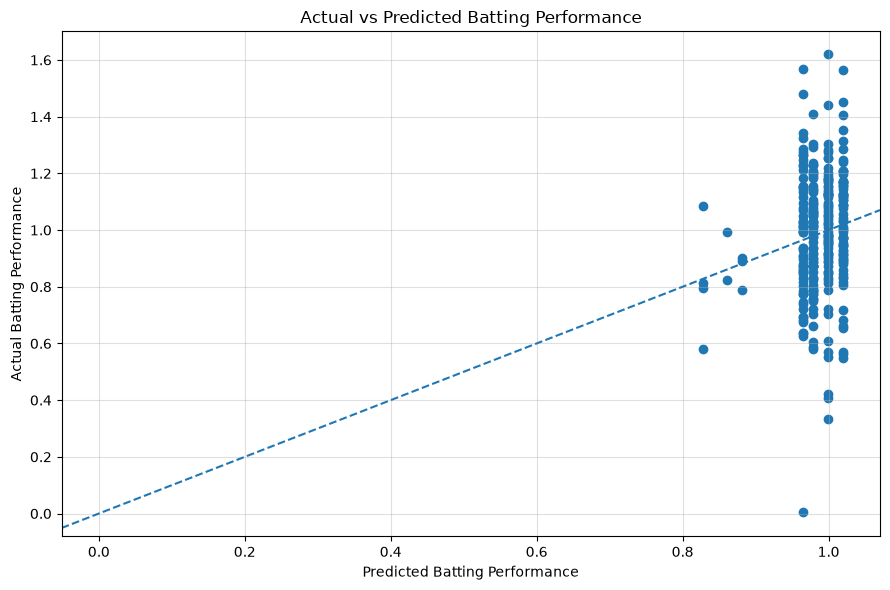

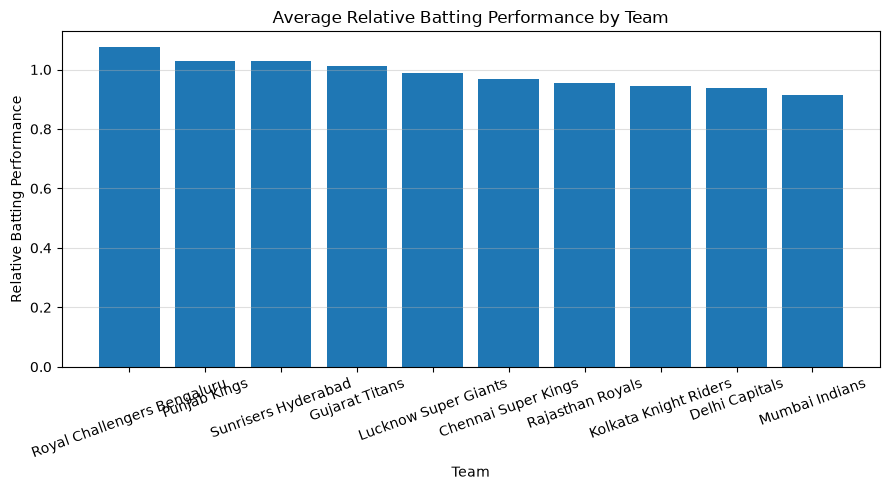

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# ==========================================
# 1. LOAD DATA
# ==========================================

df = pd.read_csv("ipl_ball_by_ball_with_venue.csv")
bowl_strength = pd.read_csv("ipl_bowling_strength.csv")

df["date"] = pd.to_datetime(df["date"])

# Standardize team names
team_aliases = {
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru"
}

df["batting_team"] = df["batting_team"].replace(team_aliases)
df["bowling_team"] = df["bowling_team"].replace(team_aliases)

bowl_strength["bowling_team"] = (
    bowl_strength["bowling_team"].replace(team_aliases)
)

# ==========================================
# 2. IDENTIFY HOME GROUNDS
# ==========================================

# Edit these names according to the venue names
# present in your CSV.

home_venue_to_team = {
    "M Chinnaswamy Stadium": "Royal Challengers Bengaluru",
    "M. Chinnaswamy Stadium": "Royal Challengers Bengaluru",

    "MA Chidambaram Stadium": "Chennai Super Kings",
    "M.A. Chidambaram Stadium": "Chennai Super Kings",

    "Wankhede Stadium": "Mumbai Indians",

    "Eden Gardens": "Kolkata Knight Riders"
}

# Normalize venue text for matching
home_venue_to_team = {
    venue.strip().lower(): team
    for venue, team in home_venue_to_team.items()
}

df["venue"] = df["venue"].fillna("").astype(str)

df["home_team"] = (
    df["venue"].str.strip().str.lower()
    .map(home_venue_to_team)
)

# Home indicator for the batting team
df["is_home"] = (
    df["batting_team"] == df["home_team"]
).astype(int)

# ==========================================
# 3. CALCULATE EACH TEAM'S INNINGS SCORE
# ==========================================

match_cols = [
    "match_id",
    "date",
    "season",
    "innings",
    "venue",
    "home_team",
    "batting_team",
    "bowling_team",
    "is_home"
]

innings_data = (
    df.groupby(match_cols, dropna=False)
    .agg(
        innings_score=("total_runs", "sum")
    )
    .reset_index()
)

# ==========================================
# 4. CALCULATE RELATIVE BATTING PERFORMANCE
# ==========================================

# Average score of all IPL innings in the dataset
average_ipl_score = innings_data["innings_score"].mean()

print("Average IPL innings score:", average_ipl_score)

# Y = Team innings score / Average IPL innings score
innings_data["relative_batting_performance"] = (
    innings_data["innings_score"] / average_ipl_score
)

# ==========================================
# 5. ADD OPPONENT BOWLING STRENGTH
# ==========================================

innings_data = innings_data.merge(
    bowl_strength[
        ["bowling_team", "bowling_strength"]
    ],
    on="bowling_team",
    how="left"
)

innings_data = innings_data.rename(
    columns={
        "bowling_strength": "OBS"
    }
)

# Remove rows where opponent bowling strength is unavailable
model_data = innings_data.dropna(
    subset=[
        "relative_batting_performance",
        "is_home",
        "OBS"
    ]
).copy()

# ==========================================
# 6. TRAIN LINEAR REGRESSION
# ==========================================

# Y = beta0 + beta1 * H + beta2 * OBS + error

X = model_data[["is_home", "OBS"]]

y = model_data["relative_batting_performance"]

model = LinearRegression()

model.fit(X, y)

# Regression coefficients
beta0 = model.intercept_
beta1 = model.coef_[0]
beta2 = model.coef_[1]

print("\nREGRESSION RESULTS")
print("-----------------------------")
print("Beta 0 (Intercept):", beta0)
print("Beta 1 (Home effect):", beta1)
print("Beta 2 (Opponent bowling):", beta2)

print("\nYour estimated equation:")
print(
    f"Y = {beta0:.4f} + "
    f"({beta1:.4f} * H) + "
    f"({beta2:.4f} * OBS)"
)

# ==========================================
# 7. CALCULATE PREDICTED PERFORMANCE
# ==========================================

model_data["predicted_batting_performance"] = (
    model.predict(X)
)

# Residual = Actual performance - Predicted performance
model_data["residual"] = (
    model_data["relative_batting_performance"] -
    model_data["predicted_batting_performance"]
)

# ==========================================
# 8. DISPLAY RESULTS
# ==========================================

result = model_data[
    [
        "match_id",
        "date",
        "season",
        "venue",
        "innings",
        "batting_team",
        "bowling_team",
        "is_home",
        "innings_score",
        "OBS",
        "relative_batting_performance",
        "predicted_batting_performance",
        "residual"
    ]
].copy()

result = result.sort_values(
    ["date", "match_id", "innings"]
).reset_index(drop=True)

print("\nMATCH-WISE BATTING PERFORMANCE")
print(result.head(20).to_string(index=False))

# ==========================================
# 9. SAVE RESULTS
# ==========================================

result.to_csv(
    "ipl_matchwise_batting_performance.csv",
    index=False
)

print("\nFile saved: ipl_matchwise_batting_performance.csv")

# ==========================================
# 10. VISUALIZATION
# ==========================================

# Actual vs predicted batting performance

plt.figure(figsize=(9, 6))

plt.scatter(
    result["predicted_batting_performance"],
    result["relative_batting_performance"]
)

plt.xlabel("Predicted Batting Performance")
plt.ylabel("Actual Batting Performance")
plt.title("Actual vs Predicted Batting Performance")

plt.axline((0, 0), slope=1, linestyle="--")
plt.grid(alpha=0.4)

plt.tight_layout()
plt.show()


# Average actual batting performance by team

team_performance = (
    result.groupby("batting_team")[
        "relative_batting_performance"
    ].mean().sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    team_performance.index,
    team_performance.values
)

plt.title("Average Relative Batting Performance by Team")
plt.xlabel("Team")
plt.ylabel("Relative Batting Performance")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.show()


Average IPL innings score: 177.1607629427793

Missing opponent batting strengths: 443

BOWLING REGRESSION RESULTS
-----------------------------
Beta 0: 1.577980514501839
Beta 1 (Home effect): -0.09981438610697387
Beta 2 (Opponent batting): -0.5431461997908965

Estimated equation:
BP = 1.5780 + (-0.0998 * H) + (-0.5431 * ABS)

MATCH-WISE BOWLING PERFORMANCE
 match_id       date  season                                         venue  innings                bowling_team                batting_team  is_home  runs_conceded  wickets_taken    ABS  relative_bowling_performance  predicted_bowling_performance  residual
  1304047 2022-03-26    2022                      Wankhede Stadium, Mumbai        1       Kolkata Knight Riders         Chennai Super Kings        0            131              5 0.2225                      1.352372                       1.457130 -0.104758
  1304047 2022-03-26    2022                      Wankhede Stadium, Mumbai        2         Chennai Super Kings       Kolkata K

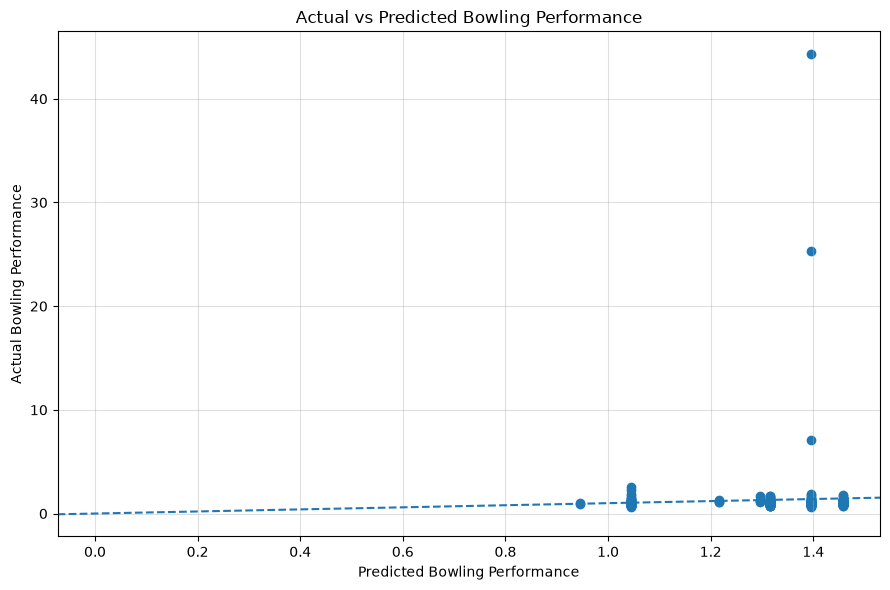

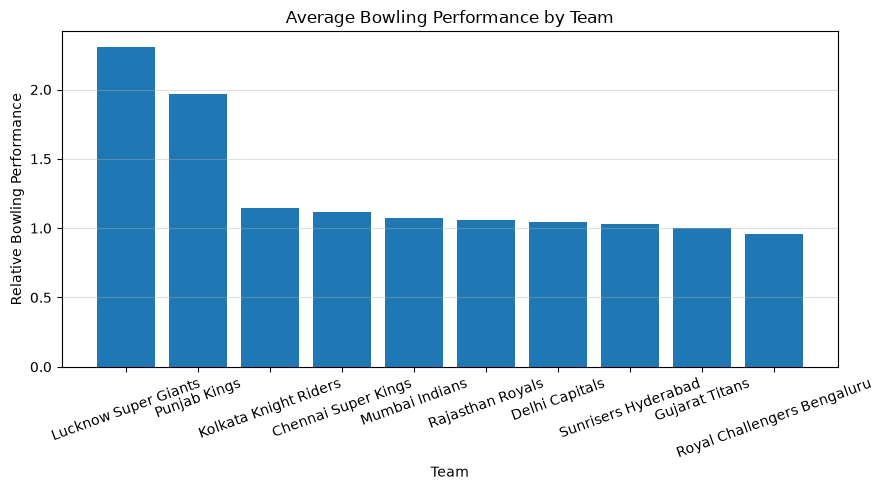

In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# ==========================================
# 1. LOAD DATA
# ==========================================

df = pd.read_csv("ipl_ball_by_ball_with_venue.csv")
bat_strength = pd.read_csv("ipl_batting_strength.csv")

df["date"] = pd.to_datetime(df["date"])

team_aliases = {
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru"
}

df["batting_team"] = df["batting_team"].replace(team_aliases)
df["bowling_team"] = df["bowling_team"].replace(team_aliases)

# CORRECTION: Rename actual CSV columns
bat_strength = bat_strength.rename(columns={
    "Team": "batting_team",
    "Batting_Strength": "batting_strength"
})

bat_strength["batting_team"] = (
    bat_strength["batting_team"].replace(team_aliases)
)

# ==========================================
# 2. IDENTIFY HOME GROUNDS
# ==========================================

home_venue_to_team = {
    "M Chinnaswamy Stadium": "Royal Challengers Bengaluru",
    "M. Chinnaswamy Stadium": "Royal Challengers Bengaluru",
    "MA Chidambaram Stadium": "Chennai Super Kings",
    "M.A. Chidambaram Stadium": "Chennai Super Kings",
    "Wankhede Stadium": "Mumbai Indians",
    "Eden Gardens": "Kolkata Knight Riders"
}

home_venue_to_team = {
    venue.strip().lower(): team
    for venue, team in home_venue_to_team.items()
}

df["venue"] = df["venue"].fillna("").astype(str)

df["home_team"] = (
    df["venue"].str.strip().str.lower()
    .map(home_venue_to_team)
)

# Home indicator for bowling team
df["is_home"] = (
    df["bowling_team"] == df["home_team"]
).astype(int)

# ==========================================
# 3. CALCULATE INNINGS DATA
# ==========================================

match_cols = [
    "match_id", "date", "season", "innings",
    "venue", "home_team", "batting_team",
    "bowling_team", "is_home"
]

innings_data = (
    df.groupby(match_cols, dropna=False)
    .agg(
        runs_conceded=("total_runs", "sum"),
        wickets_taken=("is_wicket", "sum")
    )
    .reset_index()
)

# ==========================================
# 4. RELATIVE BOWLING PERFORMANCE
# ==========================================

average_ipl_score = innings_data["runs_conceded"].mean()

print("Average IPL innings score:", average_ipl_score)

innings_data["relative_bowling_performance"] = (
    average_ipl_score /
    innings_data["runs_conceded"].replace(0, np.nan)
)

# ==========================================
# 5. ADD OPPONENT BATTING STRENGTH
# ==========================================

innings_data = innings_data.merge(
    bat_strength[["batting_team", "batting_strength"]],
    on="batting_team",
    how="left"
)

innings_data = innings_data.rename(
    columns={"batting_strength": "ABS"}
)

print("\nMissing opponent batting strengths:",
      innings_data["ABS"].isna().sum())

# ==========================================
# 6. LINEAR REGRESSION
# ==========================================

model_data = innings_data.dropna(
    subset=["relative_bowling_performance", "is_home", "ABS"]
).copy()

X = model_data[["is_home", "ABS"]]
y = model_data["relative_bowling_performance"]

model = LinearRegression()
model.fit(X, y)

beta0 = model.intercept_
beta1, beta2 = model.coef_

print("\nBOWLING REGRESSION RESULTS")
print("-----------------------------")
print("Beta 0:", beta0)
print("Beta 1 (Home effect):", beta1)
print("Beta 2 (Opponent batting):", beta2)

print("\nEstimated equation:")
print(
    f"BP = {beta0:.4f} + "
    f"({beta1:.4f} * H) + "
    f"({beta2:.4f} * ABS)"
)

# ==========================================
# 7. PREDICTED PERFORMANCE AND RESIDUAL
# ==========================================

model_data["predicted_bowling_performance"] = model.predict(X)

model_data["residual"] = (
    model_data["relative_bowling_performance"] -
    model_data["predicted_bowling_performance"]
)

# ==========================================
# 8. FINAL RESULTS
# ==========================================

result = model_data[
    [
        "match_id",
        "date",
        "season",
        "venue",
        "innings",
        "bowling_team",
        "batting_team",
        "is_home",
        "runs_conceded",
        "wickets_taken",
        "ABS",
        "relative_bowling_performance",
        "predicted_bowling_performance",
        "residual"
    ]
].copy()

result = result.sort_values(
    ["date", "match_id", "innings"]
).reset_index(drop=True)

print("\nMATCH-WISE BOWLING PERFORMANCE")
print(result.head(20).to_string(index=False))

# ==========================================
# 9. SAVE CSV
# ==========================================

result.to_csv(
    "ipl_matchwise_bowling_performance.csv",
    index=False
)

print("\nSaved successfully!")

# ==========================================
# 10. VISUALIZATION
# ==========================================

plt.figure(figsize=(9, 6))

plt.scatter(
    result["predicted_bowling_performance"],
    result["relative_bowling_performance"]
)

plt.xlabel("Predicted Bowling Performance")
plt.ylabel("Actual Bowling Performance")
plt.title("Actual vs Predicted Bowling Performance")

plt.axline((0, 0), slope=1, linestyle="--")
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


team_performance = (
    result.groupby("bowling_team")[
        "relative_bowling_performance"
    ].mean().sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    team_performance.index,
    team_performance.values
)

plt.title("Average Bowling Performance by Team")
plt.xlabel("Team")
plt.ylabel("Relative Bowling Performance")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()
